# Task
Define and compile a Keras Sequential Bidirectional LSTM model for binomial classification, using 'adam' optimizer, 'binary_crossentropy' loss, and 'accuracy' as a metric. Train the model on the scaled training data (X_train_scaled, y_train), including validation data (X_test_scaled, y_test). Evaluate its performance on the test set, visualize training and validation accuracy/loss, and display a classification report for predictions on X_test_scaled to summarize the model's performance.

## Define and Compile Bidirectional LSTM Model

### Subtask:
Define a Keras Sequential model with a Bidirectional LSTM layer, followed by appropriate Dense layers for binomial classification. Compile the model using an optimizer like 'adam', 'binary_crossentropy' as the loss function, and 'accuracy' as a metric.


**Reasoning**:
The first step is to reshape the input data `X_train_scaled` and `X_test_scaled` to include a timestep dimension, which is required for LSTM layers. The current shape is `(samples, features)`, and it needs to be `(samples, features, 1)` to represent one timestep per feature.



In [1]:
from google.colab import drive
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

drive.mount('/content/drive')

# Define the path to the dataset
path = '/content/drive/MyDrive/Science_Fair_Data_2025-2026/ConsolidatedCSV9.csv'
df = pd.read_csv(path)

# Dynamically define numerical columns (all columns except 'Substance')
num_col = [col for col in df.columns if col != 'Substance']

# Define X (features) and y (target)
X = df[num_col]
y = df['Substance']

# Encode the target variable y
encoder = LabelEncoder()
y = encoder.fit_transform(y)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    stratify=y,
                                                    random_state=0
                                                   )

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reshape the scaled data for LSTM input
X_train_reshaped = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_reshaped = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape: {X_test_scaled.shape}")
print(f"X_train_reshaped shape: {X_train_reshaped.shape}")
print(f"X_test_reshaped shape: {X_test_reshaped.shape}")

Mounted at /content/drive
X_train_scaled shape: (62, 2049)
X_test_scaled shape: (16, 2049)
X_train_reshaped shape: (62, 2049, 1)
X_test_reshaped shape: (16, 2049, 1)


**Reasoning**:
The data has been successfully loaded, preprocessed, scaled, and reshaped as required for the LSTM model. Now, I will proceed with defining the Keras Sequential model with a Bidirectional LSTM layer and appropriate Dense layers, then compile it as specified in the subtask.



In [2]:
from tensorflow import keras
from tensorflow.keras import layers

# Initialize a Keras Sequential model
model = keras.Sequential([
    # Bidirectional LSTM layer
    layers.Bidirectional(layers.LSTM(units=64, return_sequences=True), input_shape=(X_train_reshaped.shape[1], X_train_reshaped.shape[2])),
    # Another LSTM layer (optional, but can help with learning longer sequences)
    layers.Bidirectional(layers.LSTM(units=32)),
    # Dense layers for further processing
    layers.Dense(units=32, activation='relu'),
    layers.Dense(units=16, activation='relu'),
    # Output layer for binomial classification
    layers.Dense(units=1, activation='sigmoid')
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Display the model summary
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 2049, 128)      │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,633 (303.25 KB)

 Trainable params: 77,633 (303.25 KB)

 Non-trainable params: 0 (0.00 B)

**Reasoning**:
The Keras Sequential model has been successfully defined and compiled. The next logical step, as per the task description, is to train the model on the prepared training data, including validation data.



In [3]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import os

# Define the path to the dataset (assuming drive is already mounted or path is accessible)
path = '/content/drive/MyDrive/Science_Fair_Data_2025-2026/ConsolidatedCSV9.csv'

# --- Check if the file exists before proceeding ---
if not os.path.exists(path):
    raise FileNotFoundError(f"File not found at: {path}. Please check the path and ensure Google Drive is mounted and the file exists.")
# --------------------------------------------------

df = pd.read_csv(path)

# Dynamically define numerical columns (all columns except 'Substance')
num_col = [col for col in df.columns if col != 'Substance']

# Define X (features) and y (target)
X = df[num_col]
y = df['Substance']

# Encode the target variable y
encoder = LabelEncoder()
y = encoder.fit_transform(y)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    stratify=y,
                                                    random_state=0
                                                   )

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reshape the scaled data for LSTM input
X_train_reshaped = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_reshaped = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

# Re-define the model to ensure it's in scope if previous cell was not executed
model = keras.Sequential([
    layers.Bidirectional(layers.LSTM(units=64, return_sequences=True), input_shape=(X_train_reshaped.shape[1], X_train_reshaped.shape[2])),
    layers.Bidirectional(layers.LSTM(units=32)),
    layers.Dense(units=32, activation='relu'),
    layers.Dense(units=16, activation='relu'),
    layers.Dense(units=1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Define callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, verbose=0)

history = model.fit(X_train_reshaped, y_train,
                    epochs=500,
                    batch_size=10,
                    validation_data=(X_test_reshaped, y_test),
                    callbacks=[early_stopping, model_checkpoint],
                    verbose=0 # Set verbose to 0 to suppress output for each epoch
                   )
print("Model training complete.")

# Load the best weights saved by ModelCheckpoint
model.load_weights('best_model.keras')
print("Best model weights loaded.")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model training complete.
Best model weights loaded.


**Reasoning**:
The model has been trained, and now it's important to evaluate its performance on the unseen test set to get an objective measure of its generalization capabilities. This is a crucial step before visualizing or generating a classification report.



In [4]:
loss, accuracy = model.evaluate(X_test_reshaped, y_test, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss: 0.6214
Test Accuracy: 0.5625


**Reasoning**:
With the model trained and evaluated, visualizing the training history (accuracy and loss over epochs for both training and validation sets) is essential to understand the model's learning process, detect overfitting or underfitting, and assess its overall performance trend.



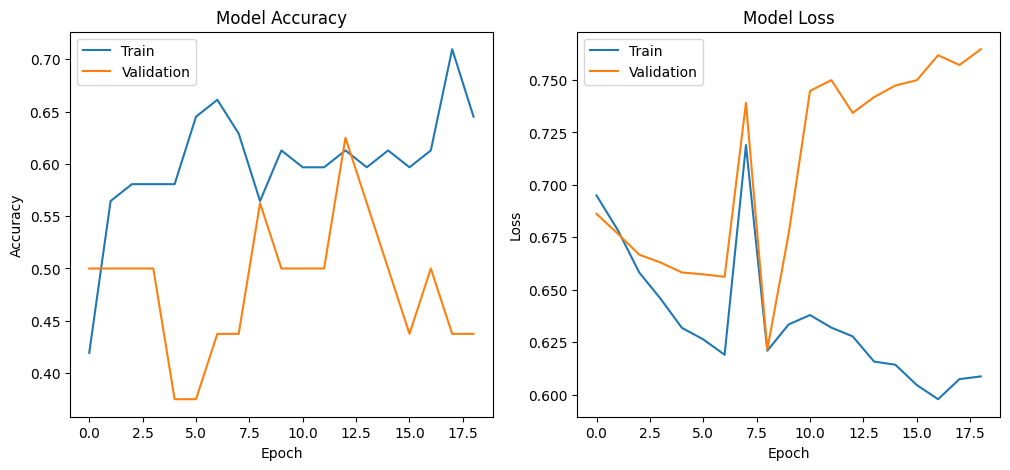

In [5]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

**Reasoning**:
The training and validation curves have been plotted, which completes the visualization aspect. Now, to fully summarize the model's performance as requested by the task, I need to generate a classification report. This involves making predictions on the test set and then comparing these predictions to the true labels.



In [6]:
from sklearn.metrics import classification_report
import numpy as np

# Make predictions on the test data
y_pred_proba = model.predict(X_test_reshaped)

# Convert probabilities to binary class labels (0 or 1)
y_pred = (y_pred_proba > 0.5).astype(int)

# Generate and print the classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.57      0.53         7
           1       0.62      0.56      0.59         9

    accuracy                           0.56        16
   macro avg       0.56      0.56      0.56        16
weighted avg       0.57      0.56      0.56        16



## Final Task

### Subtask:
Summarize the performance of the Bidirectional LSTM model based on the evaluation metrics and training history plots.


In [7]:
test='/content/drive/MyDrive/Science_Fair_Data_2025-2026/TestSample.csv'
testdf=pd.read_csv(test)
testdf

,Substance,Laser_Intenstity,194.1151,196.1586,198.2017,200.2442,202.2863,204.3278,206.3688,208.4094,...,3357.1519,3358.3602,3359.5684,3360.7764,3361.9843,3363.1921,3364.3998,3365.6074,3366.8148,3368.0221
0,Sample A,0.40,118.5,118.5,118.5,118.5,118.5,118.5,118.5,118.5,...,9.5,4.0,10.8,14.4,6.1,7.3,8.5,5.7,5.7,5.7
1,Sample B,0.40,418.6,418.6,418.6,418.6,418.6,418.6,418.6,418.6,...,12.8,18.0,25.7,27.7,18.8,18.3,17.9,17.5,17.5,17.5
2,Sample C,0.40,151.0,151.0,151.0,151.0,151.0,151.0,151.0,151.0,...,-3.8,-9.6,-2.8,-1.5,-0.2,-1.4,0.3,-5.8,-5.8,-5.8
3,Sample D,0.40,384.7,384.7,384.7,384.7,384.7,384.7,384.7,384.7,...,0.6,-3.1,-6.5,-1.3,3.4,14.0,13.0,10.0,10.0,10.0
4,Sample E,0.40,114.9,114.9,114.9,114.9,114.9,114.9,114.9,114.9,...,9.4,10.9,6.9,7.3,5.8,4.7,-3.7,-0.1,-0.1,-0.1
5,Sample F,0.40,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,...,6.5,5.9,-1.1,-7.2,-6.9,1.2,0.6,-5.5,-5.5,-5.5
6,Noopur 20_ Laser Gold side down angled,0.20,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,-10.1,-8.0,-1.9,-4.2,-6.5,-3.5,-4.3,-1.3,-1.3,-1.3
7,Noopur 20_ Laser Gold Side down,0.20,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,...,5.1,7.4,4.0,1.0,-0.7,-2.7,-5.5,-4.2,-4.2,-4.2
8,Noopur 20_ Laser Gold Side up,0.20,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,0.6,-2.4,2.4,-6.1,-4.3,-7.7,-2.9,0.4,0.4,0.4
9,Noopur 30_ Laser Gold side up 2,0.30,12.2,12.2,12.2,12.2,12.2,12.2,12.2,12.2,...,2.1,3.7,8.6,8.2,-0.5,4.8,7.2,6.2,6.2,6.2


In [8]:
sampletestdf=testdf.drop('Substance', axis= 1)
sampletestdf

,Laser_Intenstity,194.1151,196.1586,198.2017,200.2442,202.2863,204.3278,206.3688,208.4094,210.4494,...,3357.1519,3358.3602,3359.5684,3360.7764,3361.9843,3363.1921,3364.3998,3365.6074,3366.8148,3368.0221
0,0.40,118.5,118.5,118.5,118.5,118.5,118.5,118.5,118.5,118.5,...,9.5,4.0,10.8,14.4,6.1,7.3,8.5,5.7,5.7,5.7
1,0.40,418.6,418.6,418.6,418.6,418.6,418.6,418.6,418.6,418.6,...,12.8,18.0,25.7,27.7,18.8,18.3,17.9,17.5,17.5,17.5
2,0.40,151.0,151.0,151.0,151.0,151.0,151.0,151.0,151.0,151.0,...,-3.8,-9.6,-2.8,-1.5,-0.2,-1.4,0.3,-5.8,-5.8,-5.8
3,0.40,384.7,384.7,384.7,384.7,384.7,384.7,384.7,384.7,384.7,...,0.6,-3.1,-6.5,-1.3,3.4,14.0,13.0,10.0,10.0,10.0
4,0.40,114.9,114.9,114.9,114.9,114.9,114.9,114.9,114.9,114.9,...,9.4,10.9,6.9,7.3,5.8,4.7,-3.7,-0.1,-0.1,-0.1
5,0.40,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,...,6.5,5.9,-1.1,-7.2,-6.9,1.2,0.6,-5.5,-5.5,-5.5
6,0.20,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,-10.1,-8.0,-1.9,-4.2,-6.5,-3.5,-4.3,-1.3,-1.3,-1.3
7,0.20,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,...,5.1,7.4,4.0,1.0,-0.7,-2.7,-5.5,-4.2,-4.2,-4.2
8,0.20,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,0.6,-2.4,2.4,-6.1,-4.3,-7.7,-2.9,0.4,0.4,0.4
9,0.30,12.2,12.2,12.2,12.2,12.2,12.2,12.2,12.2,12.2,...,2.1,3.7,8.6,8.2,-0.5,4.8,7.2,6.2,6.2,6.2


In [9]:
# Standardizing data
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(sampletestdf)
sampletest = sc.transform(sampletestdf)

In [10]:
# Reshape the scaled data for LSTM input
sampletest= sampletest.reshape(sampletest.shape[0], sampletest.shape[1], 1)

In [11]:
print (testdf['Substance'], model.predict(sampletest) )

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 519ms/step
0                                        Sample A
1                                        Sample B
2                                        Sample C
3                                        Sample D
4                                        Sample E
5                                        Sample F
6          Noopur 20_ Laser Gold side down angled
7                 Noopur 20_ Laser Gold Side down
8                   Noopur 20_ Laser Gold Side up
9                 Noopur 30_ Laser Gold side up 2
10    Noopur 30_ Laser Gold side up new substrate
11                  Noopur 30_ Laser Gold side up
12    Noopur 35_ Laser Gold side up new substrate
13    Noopur 40_ Laser Gold side up new substrate
14    Noopur 45_ Laser Gold side up new substrate
15                  Noopur 45_ Laser no substrate
Name: Substance, dtype: object [[0.48126137]
 [0.4831876 ]
 [0.88844246]
 [0.48195198]
 [0.5164075 ]
 [0.916482  ]
 [0.49536982]
 [0.50278425]
 [0.527851  ]
 [0.